In [1]:
import json
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../gw_prototype')
from fisheye_camera import CameraCalibrationParameters
from detection_area import CameraConfiguration, DetectionArea

%load_ext autoreload
%autoreload 2

In [2]:
IMG_PTHS = [
    "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe/images/train/4.2_batch1____4.2_H_cam_251_menivimmr_139.jpg",
    "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe/images/train/4.2_batch1____4.2_H_cam_258_MenivimDesk_2.jpg",
    "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe/images/train/4.2_batch1____4.2_H_cam_299_menivimrec_92.jpg",
    "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe/images/train/4.2_batch1____4.2_H_cam_320_menivimOS_214.jpg",
]

HEIHGTS = [251, 258, 299, 320]

In [3]:
imgs = []
for img_pth in IMG_PTHS:
    img = cv2.imread(img_pth)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    if img is None:
        raise ValueError(f"Image not found: {img_pth}")
    imgs.append(img)

cam3 width = 928.0, height = 539.0
cam4 width = 1057.0, height = 610.0
cam4 with limit width = 931.0, height = 537.0


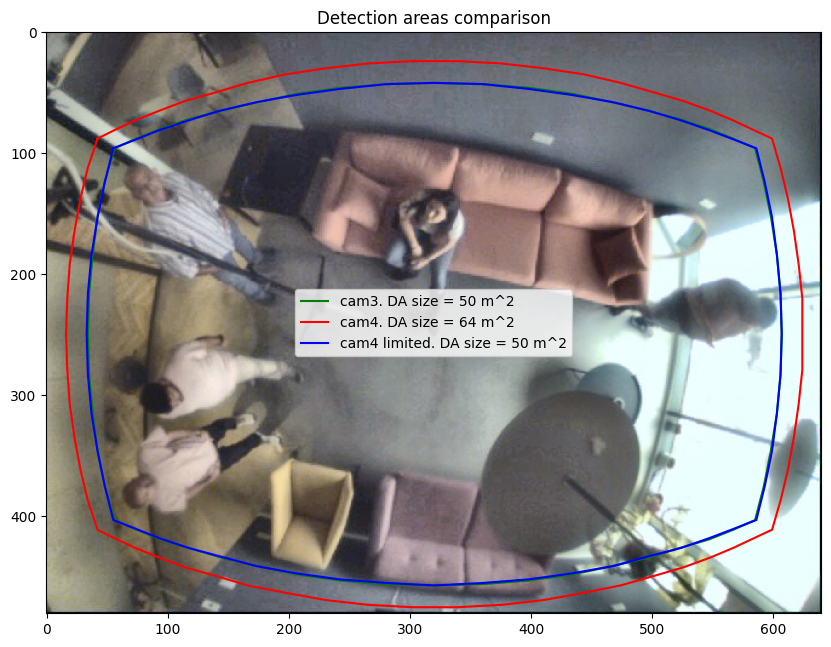

In [7]:
plt.figure(figsize=(10, 10))

H = HEIHGTS[-1]

with open("params/cam4_2_4_rev_b.json", "rt") as f:
    data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["LENS_PARAMS"]["CX"],
    data["LENS_PARAMS"]["CY"],
    data["LENS_PARAMS"]["FX"],
    data["LENS_PARAMS"]["FY"],
    data["LENS_PARAMS"]["K0"],
    data["LENS_PARAMS"]["K1"],
    data["LENS_PARAMS"]["K2"],
    data["LENS_PARAMS"]["K3"],
)

cam_config = CameraConfiguration(
    calibration_params,
    135,
    109,
    H,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config, True)

poly = np.array(da_cam3.polygon_in_pixels())
print(f"cam3 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")
 
plt.imshow(img)
plt.plot(poly[:, 0], poly[:, 1], 'g-', label=f"cam3. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")

cam_config = CameraConfiguration(
    calibration_params,
    data["LENS_PARAMS"]["FOV_X"],
    data["LENS_PARAMS"]["FOV_Y"],
    H,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'r-', label=f"cam4. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

da_cam3 = DetectionArea(cam_config, True)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'b-', label=f"cam4 limited. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 with limit width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

plt.ylim(480, 0)

plt.title("Detection areas comparison")
plt.legend()

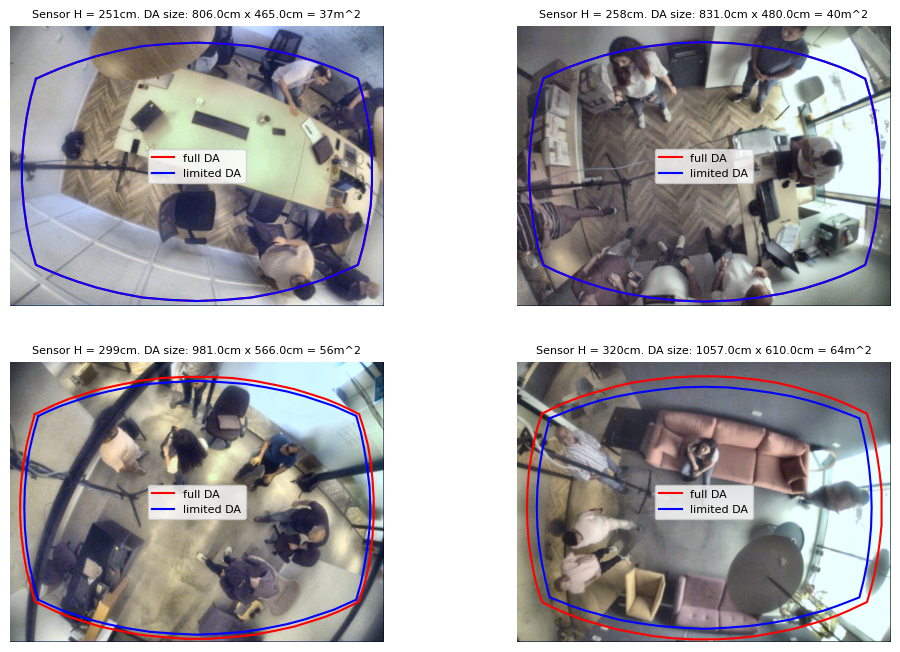

In [10]:
with open("params/cam4_2_4_rev_b.json", "rt") as f:
    data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["LENS_PARAMS"]["CX"],
    data["LENS_PARAMS"]["CY"],
    data["LENS_PARAMS"]["FX"],
    data["LENS_PARAMS"]["FY"],
    data["LENS_PARAMS"]["K0"],
    data["LENS_PARAMS"]["K1"],
    data["LENS_PARAMS"]["K2"],
    data["LENS_PARAMS"]["K3"],
)

plt.figure(figsize=(12, 8))

for h, img in zip(HEIHGTS, imgs):
    cam_config = CameraConfiguration(
        calibration_params,
        data["LENS_PARAMS"]["FOV_X"],
        data["LENS_PARAMS"]["FOV_Y"],
        h,
        data["IMG_W"],
        data["IMG_H"]
    )

    da = DetectionArea(cam_config)
    poly = np.array(da.polygon_in_pixels())

    plt.subplot(2, 2, HEIHGTS.index(h) + 1)
    plt.imshow(img)
    plt.plot(poly[:, 0], poly[:, 1], 'r-', label="full DA")
    
    plt.title(f"Sensor H = {h}cm. DA size: {da.m_rectangle_cm.w}cm x {da.m_rectangle_cm.h}cm = {round(da.m_rectangle_cm.h * da.m_rectangle_cm.w / 10000)}m^2", fontsize=8)
    
    da = DetectionArea(cam_config, True)
    poly = np.array(da.polygon_in_pixels())
    plt.plot(poly[:, 0], poly[:, 1], 'b-', label="limited DA")

    plt.legend(fontsize=8)
    # plt.tight_layout()
    
    plt.axis('off')